In [ ]:
import os
import tensorflow as tf
from tensorflow.keras.applications import VGG16, ResNet50, MobileNet
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Flatten, Dropout
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from sklearn.metrics import classification_report, roc_auc_score
import matplotlib.pyplot as plt
import numpy as np
from google.colab import drive

In [ ]:

drive.mount('/content/drive')


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
caminho_dados = '/content/drive/My Drive/Forest_Fire_BigData'


In [ ]:
#  ImageDataGenerator para normalizar as imagens e fazer divisão treino/validação
datagen = ImageDataGenerator(rescale=1./255, validation_split=0.2)  # 80% treino, 20% validação




In [ ]:
# Carregar os dados de treino
train_data = datagen.flow_from_directory(caminho_dados,
                                         target_size=(128, 128),  # Redimensionar imagens
                                         batch_size=32,
                                         class_mode='binary',  # Para classificação binária
                                         subset='training')  # Subconjunto de treino

Found 1475 images belonging to 2 classes.


In [ ]:
# Carregar os dados de validação
val_data = datagen.flow_from_directory(caminho_dados,
                                       target_size=(128, 128),  # Redimensionar imagens
                                       batch_size=32,
                                       class_mode='binary',
                                       subset='validation')  # Subconjunto de validação


Found 367 images belonging to 2 classes.


In [ ]:
# Função para adicionar camadas de classificação ao modelo base
def build_model(base_model):
    model = Sequential([
        base_model,
        Flatten(),
        Dense(128, activation='relu'),
        Dropout(0.5),
        Dense(1, activation='sigmoid')  # Saída binária
    ])
    return model

In [ ]:

# Modelos pré-treinados (Transfer Learning)
vgg16_base = VGG16(include_top=False, input_shape=(128, 128, 3))
resnet50_base = ResNet50(include_top=False, input_shape=(128, 128, 3))
mobilenet_base = MobileNet(include_top=False, input_shape=(128, 128, 3))


In [ ]:
# Congelar os pesos dos modelos base para transfer learning
for base_model in [vgg16_base, resnet50_base, mobilenet_base]:
    base_model.trainable = False


In [ ]:
# CNN Simples
cnn_simple = Sequential([
    tf.keras.layers.Conv2D(32, (3, 3), activation='relu', input_shape=(128, 128, 3)),
    tf.keras.layers.MaxPooling2D((2, 2)),
    tf.keras.layers.Conv2D(64, (3, 3), activation='relu'),
    tf.keras.layers.MaxPooling2D((2, 2)),
    Flatten(),
    Dense(128, activation='relu'),
    Dropout(0.5),
    Dense(1, activation='sigmoid')
])

/usr/local/lib/python3.10/dist-packages/keras/src/layers/convolutional/base_conv.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [ ]:
# Criar modelos completos
models = {
    'CNN Simples': cnn_simple,
    'VGG16': build_model(vgg16_base),
    'ResNet50': build_model(resnet50_base),
    'MobileNet': build_model(mobilenet_base)
}


In [ ]:
history_dict = {}

In [ ]:


for name, model in models.items():
    print(f'Treinando {name}...')
    model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
    # Armazenar o histórico de treinamento para cada modelo
    history = model.fit(train_data, validation_data=val_data, epochs=5)
    history_dict[name] = history  # Armazenar o histórico


Treinando CNN Simples...
Epoch 1/5


/usr/local/lib/python3.10/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


47/47 ━━━━━━━━━━━━━━━━━━━━ 48s 949ms/step - accuracy: 0.8068 - loss: 0.5797 - val_accuracy: 0.9074 - val_loss: 0.2650
Epoch 2/5
47/47 ━━━━━━━━━━━━━━━━━━━━ 46s 959ms/step - accuracy: 0.9516 - loss: 0.1686 - val_accuracy: 0.9128 - val_loss: 0.2186
Epoch 3/5
47/47 ━━━━━━━━━━━━━━━━━━━━ 80s 912ms/step - accuracy: 0.9685 - loss: 0.1136 - val_accuracy: 0.9237 - val_loss: 0.2293
Epoch 4/5
47/47 ━━━━━━━━━━━━━━━━━━━━ 45s 936ms/step - accuracy: 0.9597 - loss: 0.1091 - val_accuracy: 0.9264 - val_loss: 0.2282
Epoch 5/5
47/47 ━━━━━━━━━━━━━━━━━━━━ 46s 952ms/step - accuracy: 0.9732 - loss: 0.0851 - val_accuracy: 0.9210 - val_loss: 0.2412
Treinando VGG16...
Epoch 1/5
47/47 ━━━━━━━━━━━━━━━━━━━━ 342s 7s/step - accuracy: 0.7851 - loss: 0.4650 - val_accuracy: 0.9455 - val_loss: 0.1875
Epoch 2/5
47/47 ━━━━━━━━━━━━━━━━━━━━ 380s 7s/step - accuracy: 0.9719 - loss: 0.0928 - val_accuracy: 0.9537 - val_loss: 0.1696
Epoch 3/5
47/47 ━━━━━━━━━━━━━━━━━━━━ 352s 8s/step - accuracy: 0.9800 - loss: 0.0651 - val_accuracy:

In [ ]:
# Função para plotar os gráficos de perda e acurácia
def plot_history(history, model_name):
    acc = history.history['accuracy']
    val_acc = history.history['val_accuracy']
    loss = history.history['loss']
    val_loss = history.history['val_loss']
    epochs = range(1, len(acc) + 1)

    plt.figure(figsize=(14, 5))

    # Plotar acurácia
    plt.subplot(1, 2, 1)
    plt.plot(epochs, acc, 'bo', label='Acurácia de treino')
    plt.plot(epochs, val_acc, 'b', label='Acurácia de validação')
    plt.title(f'Acurácia do Modelo {model_name}')
    plt.xlabel('Épocas')
    plt.ylabel('Acurácia')
    plt.legend()

    # Plotar perda
    plt.subplot(1, 2, 2)
    plt.plot(epochs, loss, 'ro', label='Perda de treino')
    plt.plot(epochs, val_loss, 'r', label='Perda de validação')
    plt.title(f'Perda do Modelo {model_name}')
    plt.xlabel('Épocas')
    plt.ylabel('Perda')
    plt.legend()

    plt.show()


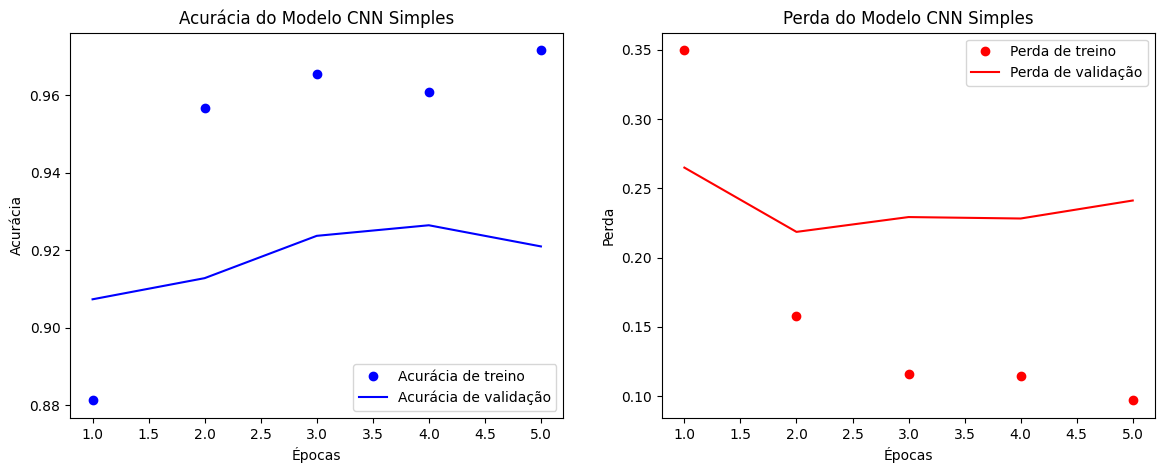

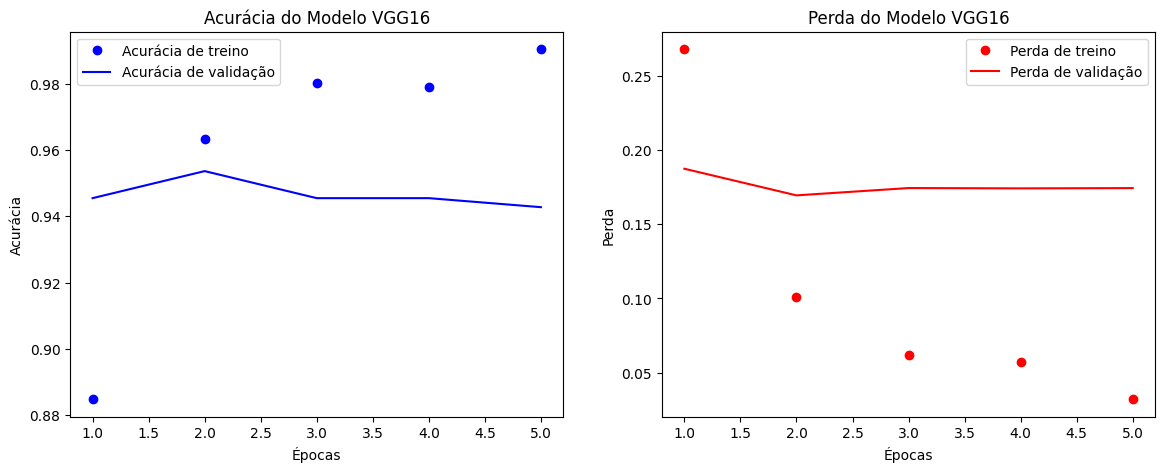

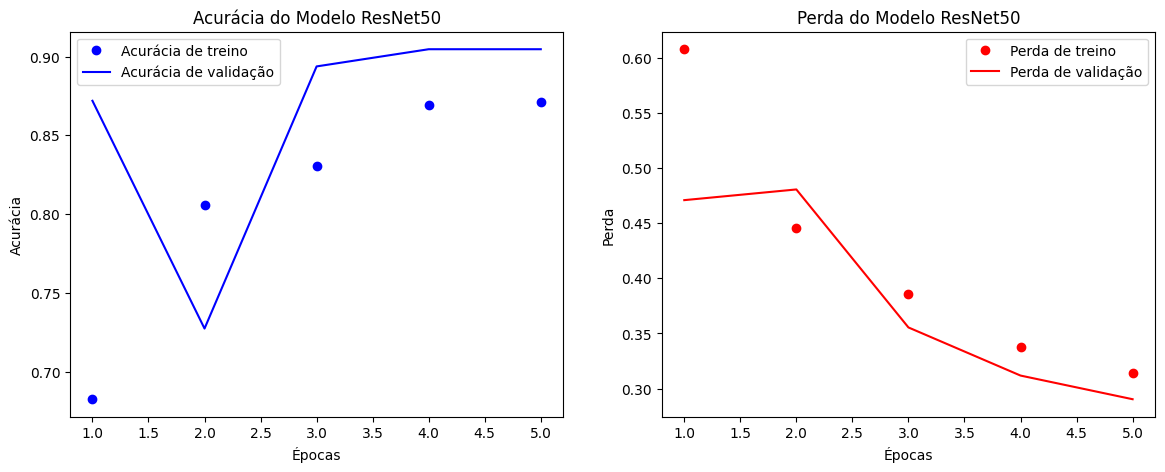

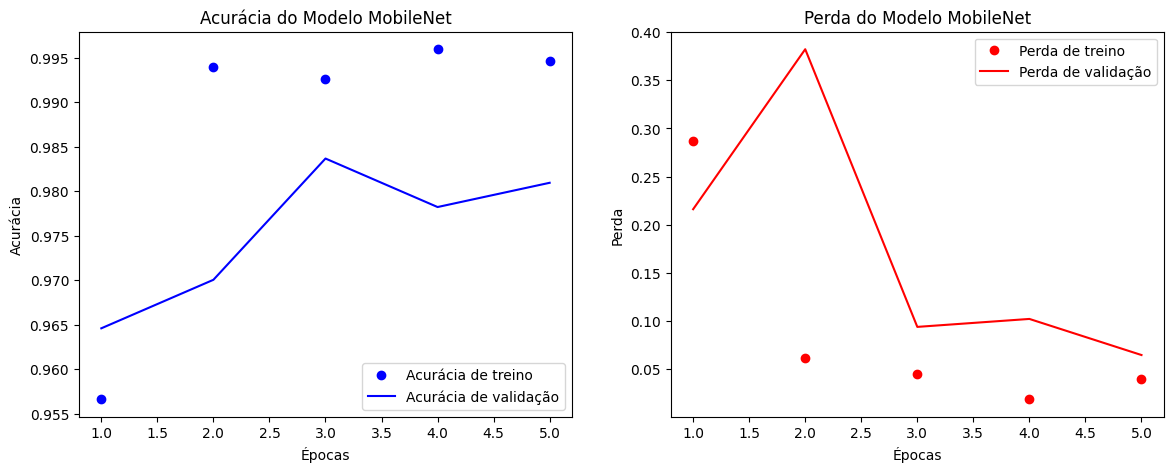

In [ ]:
# Plotar gráficos para cada modelo
for name, history in history_dict.items():
    plot_history(history, name)


In [ ]:
# Avaliação e Comparação
for name, model in models.items():
    print(f'Avaliando {name}...')
    val_preds = model.predict(val_data)
    val_labels = val_data.classes
    val_preds = (val_preds > 0.5).astype(int)

    # Relatório de Classificação
    print(f"Relatório de Classificação para {name}:")
    print(classification_report(val_labels, val_preds))

    # AUC
    auc = roc_auc_score(val_labels, val_preds)
    print(f"AUC para {name}: {auc}")

Avaliando CNN Simples...
12/12 ━━━━━━━━━━━━━━━━━━━━ 5s 368ms/step
Relatório de Classificação para CNN Simples:
              precision    recall  f1-score   support

           0       0.50      0.55      0.52       185
           1       0.49      0.45      0.47       182

    accuracy                           0.50       367
   macro avg       0.50      0.50      0.49       367
weighted avg       0.50      0.50      0.49       367

AUC para CNN Simples: 0.4955004455004455
Avaliando VGG16...
12/12 ━━━━━━━━━━━━━━━━━━━━ 66s 6s/step
Relatório de Classificação para VGG16:
              precision    recall  f1-score   support

           0       0.49      0.49      0.49       185
           1       0.48      0.48      0.48       182

    accuracy                           0.49       367
   macro avg       0.48      0.48      0.48       367
weighted avg       0.48      0.49      0.48       367

AUC para VGG16: 0.484956934956935
Avaliando ResNet50...
12/12 ━━━━━━━━━━━━━━━━━━━━ 25s 2s/step
Re

12/12 ━━━━━━━━━━━━━━━━━━━━ 7s 510ms/step - accuracy: 0.9269 - loss: 0.2203
12/12 ━━━━━━━━━━━━━━━━━━━━ 68s 6s/step - accuracy: 0.9508 - loss: 0.1720
12/12 ━━━━━━━━━━━━━━━━━━━━ 23s 2s/step - accuracy: 0.8767 - loss: 0.4472
12/12 ━━━━━━━━━━━━━━━━━━━━ 5s 404ms/step - accuracy: 0.9771 - loss: 0.1155


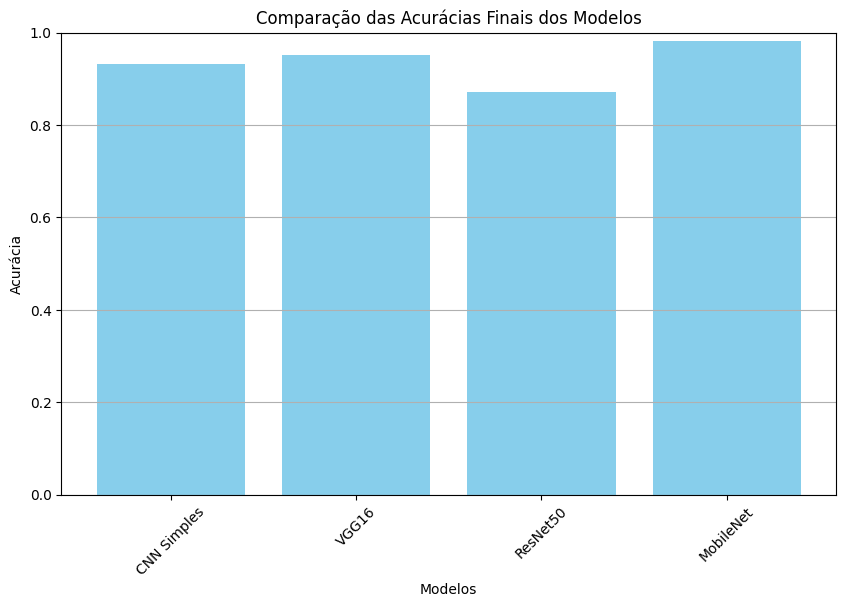

In [ ]:
# Gráfico Comparativo de Acurácias Finais
final_accuracies = {name: model.evaluate(val_data)[1] for name, model in models.items()}

plt.figure(figsize=(10, 6))
plt.bar(final_accuracies.keys(), final_accuracies.values(), color='skyblue')
plt.ylim(0, 1)
plt.title('Comparação das Acurácias Finais dos Modelos')
plt.xlabel('Modelos')
plt.ylabel('Acurácia')
plt.grid(axis='y')
plt.xticks(rotation=45)
plt.show()
